# Adaptive Quantum COBYLA vs  Quantum COBYLA

**가설 H1:** 동일한 데이터·초기화·평가 예산에서 Adaptive Quantum Direction COBYLA의 검증 MSE가 Quantum Direction COBYLA보다 작습니다.

모델: Linear, Tanh MLP, Residual MLP, Transformer. 규모 S/M/L/XL, LLM급은 계산량 분석 전용입니다.
이 실험은 Qiskit statevector 시뮬레이션이며 양자 우월성을 검증하지 않습니다.

In [1]:
import math, time
import numpy as np
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
from modules.optimizers.QuantumDirectionCOBYLA import QuantumDirectionCOBYLA
from modules.optimizers.AdaptiveQuantumDirectionCOBYLA import AdaptiveQuantumDirectionCOBYLA
import qiskit
print("torch", torch.__version__, "qiskit", qiskit.__version__)

torch 2.8.0+xpu qiskit 2.6.2


## 사전 설정

각 seed별 동일 데이터·초기화로 paired 비교합니다. Adaptive는 step당 baseline objective를 1회 추가 호출하므로 Fixed COBYLA의 maxiter=12, Adaptive maxiter=11로 총 평가 횟수를 맞춥니다. 실제 호출 횟수를 검증합니다. 검증 데이터는 최적화에 사용하지 않습니다.

In [2]:
SEEDS = [11, 23, 37, 53, 71]
ROUNDS = 8
EVALS_PER_ROUND = 12
MAX_PARAMS = 20000
RUN = [("linear","S"), ("mlp","S"), ("residual","S"), ("transformer","S")]
torch.set_num_threads(min(4,torch.get_num_threads()))
SCALES = {"S":(8,1), "M":(64,2), "L":(256,6), "XL":(1024,24)}

In [3]:
class Residual(nn.Module):
    def __init__(self,w,d):
        super().__init__()
        self.inp=nn.Linear(8,w)
        self.blocks=nn.ModuleList([nn.Sequential(nn.Linear(w,w),nn.GELU(),nn.Linear(w,w)) for _ in range(d)])
        self.out=nn.Linear(w,1)
    def forward(self,x):
        z=self.inp(x)
        for block in self.blocks: z=z+block(z)/math.sqrt(z.shape[-1])
        return self.out(z)

class Transformer(nn.Module):
    def __init__(self,w,d):
        super().__init__()
        self.embed=nn.Linear(1,w)
        layer=nn.TransformerEncoderLayer(d_model=w,nhead=2,dim_feedforward=4*w,dropout=0.,batch_first=True)
        self.encoder=nn.TransformerEncoder(layer,num_layers=d,enable_nested_tensor=False)
        self.out=nn.Linear(w,1)
    def forward(self,x): return self.out(self.encoder(self.embed(x.unsqueeze(-1))).mean(1))

def model_for(family,scale):
    w,d=SCALES[scale]
    if family=="linear": return nn.Linear(8,1)
    if family=="mlp":
        layers=[nn.Linear(8,w),nn.Tanh()]
        for _ in range(d-1): layers.extend([nn.Linear(w,w),nn.Tanh()])
        return nn.Sequential(*layers,nn.Linear(w,1))
    if family=="residual": return Residual(w,d)
    if family=="transformer": return Transformer(w,d)
    raise ValueError(family)

def nparams(m): return sum(p.numel() for p in m.parameters())
catalog=pd.DataFrame([{"family":f,"scale":s,"parameters":nparams(model_for(f,s))} for f in ["linear","mlp","residual","transformer"] for s in SCALES])
catalog["runnable"]=catalog.parameters<=MAX_PARAMS
display(catalog)

,family,scale,parameters,runnable
0,linear,S,9,True
1,linear,M,9,True
2,linear,L,9,True
3,linear,XL,9,True
4,mlp,S,81,True
5,mlp,M,4801,True
6,mlp,L,331521,False
7,mlp,XL,24151041,False
8,residual,S,225,True
9,residual,M,17281,True


## LLM 규모 분석 (실제 학습하지 않음)

float32 가중치 저장량의 하한과 파라미터당 1 shot 기준 방향 샘플 수를 계산합니다. optimizer의 추가 메모리·활성값은 제외합니다.

In [4]:
llm_sizes=[("10M",10_000_000),("100M",100_000_000),("1B",1_000_000_000),("7B",7_000_000_000),("70B",70_000_000_000)]
display(pd.DataFrame([{"scale":n,"parameters":p,"weights_GiB":4*p/2**30,"shots_8_rounds":p*ROUNDS,"executed":False} for n,p in llm_sizes]))

,scale,parameters,weights_GiB,shots_8_rounds,executed
0,10M,10000000,0.037253,80000000,False
1,100M,100000000,0.372529,800000000,False
2,1B,1000000000,3.725290,8000000000,False
3,7B,7000000000,26.077032,56000000000,False
4,70B,70000000000,260.770321,560000000000,False


In [5]:
def dataset(seed):
    rng=np.random.default_rng(seed)
    x=rng.normal(size=(256,8)).astype("float32")
    y=(.7*np.sin(x[:,0])+.4*x[:,1]**2-.5*x[:,2]*x[:,3]+.2*x[:,4]+rng.normal(0,.05,256)).astype("float32")
    order=rng.permutation(256)
    return [torch.from_numpy(v) for v in (x[order[:192]],y[order[:192],None],x[order[192:]],y[order[192:],None])]

def experiment(family,scale,seed,adaptive):
    torch.manual_seed(seed+1000)
    model=model_for(family,scale)
    if nparams(model)>MAX_PARAMS: raise ValueError("parameter limit exceeded")
    xt,yt,xv,yv=dataset(seed)
    calls=0
    def objective():
        nonlocal calls
        calls+=1
        with torch.no_grad(): return float(nn.functional.mse_loss(model(xt),yt))
    def measure(x,y):
        with torch.no_grad(): return float(nn.functional.mse_loss(model(x),y))
    kw=dict(steps=1,seed=seed,cobyla_radius=.1)
    if adaptive:
        opt=AdaptiveQuantumDirectionCOBYLA(direction_cobyla_evaluations=EVALS_PER_ROUND-1,adaptive_learning_rate=.1,**kw)
    else:
        opt=QuantumDirectionCOBYLA(direction_cobyla_evaluations=EVALS_PER_ROUND,**kw)
    opt.prepare(model)
    history=[(0,measure(xt,yt),measure(xv,yv))]
    start=time.perf_counter()
    for r in range(1,ROUNDS+1):
        before=calls
        info=opt.optimize(objective)
        assert calls-before==EVALS_PER_ROUND,(calls-before,EVALS_PER_ROUND)
        history.append((r,measure(xt,yt),measure(xv,yv)))
    return {"family":family,"scale":scale,"seed":seed,"algorithm":"Adaptive cobyla" if adaptive else "cobyla",
            "parameters":nparams(model),"train_mse":history[-1][1],"val_mse":history[-1][2],
            "objective_calls":calls,"elapsed_seconds":time.perf_counter()-start,"history":history}

results=[]
for family,scale in RUN:
    for seed in SEEDS:
        for adaptive in (False,True):
            result=experiment(family,scale,seed,adaptive)
            results.append(result)
            print(family,scale,seed,result["algorithm"],round(result["val_mse"],6))
df=pd.DataFrame([{k:v for k,v in r.items() if k!="history"} for r in results])
display(df)

linear S 11 cobyla 0.788796
linear S 11 Adaptive cobyla 0.788567
linear S 23 cobyla 0.720601
linear S 23 Adaptive cobyla 0.722124
linear S 37 cobyla 0.911537
linear S 37 Adaptive cobyla 0.911238
linear S 53 cobyla 0.430433
linear S 53 Adaptive cobyla 0.429569
linear S 71 cobyla 1.15436
linear S 71 Adaptive cobyla 1.156831
mlp S 11 cobyla 0.844975
mlp S 11 Adaptive cobyla 0.844595
mlp S 23 cobyla 0.543805
mlp S 23 Adaptive cobyla 0.567056
mlp S 37 cobyla 1.078616
mlp S 37 Adaptive cobyla 1.084065
mlp S 53 cobyla 0.723703
mlp S 53 Adaptive cobyla 0.722929
mlp S 71 cobyla 0.971126
mlp S 71 Adaptive cobyla 0.96999
residual S 11 cobyla 0.564326
residual S 11 Adaptive cobyla 0.547167
residual S 23 cobyla 0.776128
residual S 23 Adaptive cobyla 0.780163
residual S 37 cobyla 0.903828
residual S 37 Adaptive cobyla 0.902734
residual S 53 cobyla 0.570258
residual S 53 Adaptive cobyla 0.579877
residual S 71 cobyla 1.057409
residual S 71 Adaptive cobyla 1.080017
transformer S 11 cobyla 0.635022
tran

,family,scale,seed,algorithm,parameters,train_mse,val_mse,objective_calls,elapsed_seconds
0,linear,S,11,cobyla,9,0.534109,0.788796,96,0.016784
1,linear,S,11,Adaptive cobyla,9,0.534393,0.788567,96,0.016186
2,linear,S,23,cobyla,9,0.738120,0.720601,96,0.009083
3,linear,S,23,Adaptive cobyla,9,0.738803,0.722124,96,0.012686
4,linear,S,37,cobyla,9,0.582575,0.911537,96,0.009578
5,linear,S,37,Adaptive cobyla,9,0.582940,0.911238,96,0.013587
6,linear,S,53,cobyla,9,0.833844,0.430433,96,0.010539
7,linear,S,53,Adaptive cobyla,9,0.836848,0.429569,96,0.013367
8,linear,S,71,cobyla,9,0.739567,1.154360,96,0.009933
9,linear,S,71,Adaptive cobyla,9,0.739712,1.156831,96,0.013522


## Paired 가설 검정

차이 = Adaptive − Fixed. 음수면 Adaptive 우세. Seed 5개의 bootstrap CI는 탐색적 추정입니다. 모델별 다중 비교를 고려해야 하며, CI가 0을 포함하면 가설을 입증하지 못합니다.

,family,scale,pairs,mean_adaptive_minus_fixed,ci95_low,ci95_high,adaptive_wins
0,linear,S,5,0.000520,-0.000511,0.001727,3
1,mlp,S,5,0.005282,-0.000840,0.014813,3
2,residual,S,5,0.003602,-0.008591,0.014815,2
3,transformer,S,5,-0.008781,-0.042921,0.015114,3


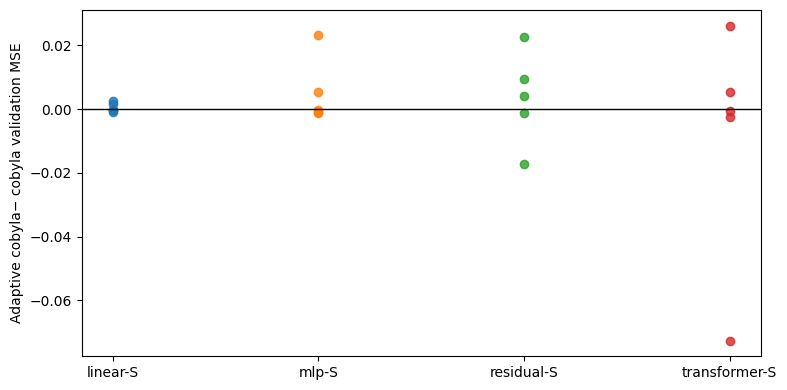

In [6]:
paired=df.pivot(index=["family","scale","seed"],columns="algorithm",values="val_mse").dropna()
paired["diff"]=paired["Adaptive cobyla"]-paired["cobyla"]
rng=np.random.default_rng(20261121)
rows=[]
for (family,scale),group in paired.groupby(level=["family","scale"]):
    d=group["diff"].to_numpy()
    means=rng.choice(d,size=(5000,len(d)),replace=True).mean(axis=1)
    lo,hi=np.quantile(means,[.025,.975])
    rows.append({"family":family,"scale":scale,"pairs":len(d),"mean_adaptive_minus_fixed":d.mean(),
                 "ci95_low":lo,"ci95_high":hi,"adaptive_wins":int((d<0).sum())})
display(pd.DataFrame(rows))
fig,ax=plt.subplots(figsize=(8,4))
for (f,s),g in paired.groupby(level=["family","scale"]):
    ax.scatter([f+"-"+s]*len(g),g["diff"],alpha=.8)
ax.axhline(0,color="black",lw=1)
ax.set_ylabel("Adaptive cobyla− cobyla validation MSE")
plt.tight_layout()
plt.show()

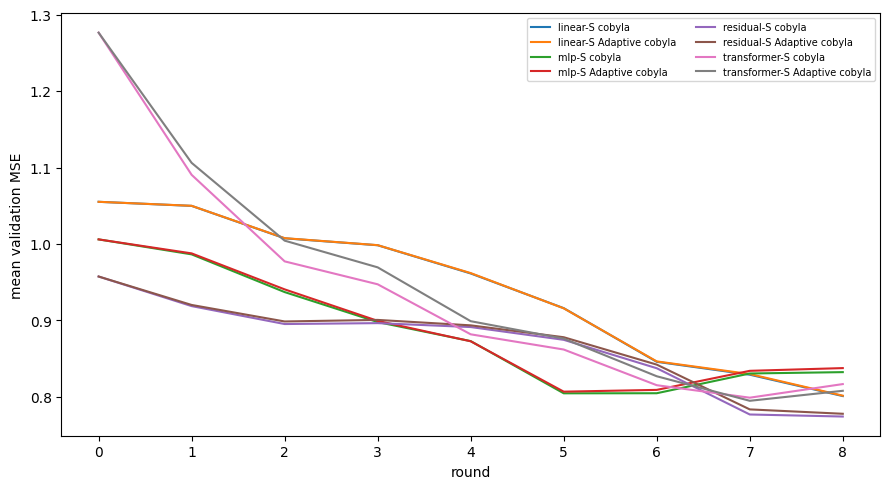

In [7]:
fig,ax=plt.subplots(figsize=(9,5))
for family,scale in RUN:
    for alg in ("cobyla","Adaptive cobyla"):
        rows=[r for r in results if r["family"]==family and r["scale"]==scale and r["algorithm"]==alg]
        curves=np.array([[h[2] for h in r["history"]] for r in rows])
        ax.plot(range(ROUNDS+1),curves.mean(0),label=f"{family}-{scale} {alg}")
ax.set_xlabel("round")
ax.set_ylabel("mean validation MSE")
ax.legend(fontsize=7,ncol=2)
plt.tight_layout()
plt.show()

## 한계 및 재현

- 기본 실험은 S 규모만 실행합니다. M/L/XL은 모델 구조와 파라미터 수만 계산하며, 실제 실행하려면 RUN과 MAX_PARAMS를 의식적으로 변경해야 합니다.
- 7B/70B는 실제 모델이 아니라 규모 추정입니다. 기존 구현은 파라미터 수에 비례하는 방향 샘플링·복제를 수행합니다.
- Qiskit statevector 시뮬레이션은 실제 양자 하드웨어 성능을 뜻하지 않습니다.
- 학습/검증 데이터는 synthetic이며 seed 5개로는 확정적 결론을 내릴 수 없습니다.
- 실행 환경에는 torch, numpy, scipy, pandas, matplotlib, qiskit 및 core.git의 공통 모듈이 필요합니다.
- 실제 결과가 없으므로 현재 가설 채택 여부는 알 수 없습니다.